In [138]:
import geopandas as gpd
import pandas as pd
import geodatasets
import json
from pathlib import Path
import matplotlib.pyplot as plt
import contextily as cx
from shapely.geometry import box, shape
import string


In [4]:
with open("candidate_places_dict.json", "r") as f:
    candidate_places_dict = json.load(f)
len(candidate_places_dict)

2888

In [172]:
unique_candidate_names = set()
sanitised_candidate_places = {}

def tidy(placenm):
    if placenm and placenm[-1] in string.punctuation:
        return placenm[:-1].replace("!", "").replace("?", "").strip()
    return placenm.replace("!", "").replace("?", "").strip()

for id, place_list in candidate_places_dict.items():
    sanitised_place_list = list(set([tidy(s) for s in place_list]))
    sanitised_candidate_places[id] = sanitised_place_list

    for placename in sanitised_place_list:
        unique_candidate_names.add(placename)

len(unique_candidate_names)

# There are 7300 candidate place names.


7300

In [173]:
with open("sanitised_candidate_places.json", "w") as f:
    json.dump(sanitised_candidate_places, f)

<Axes: >

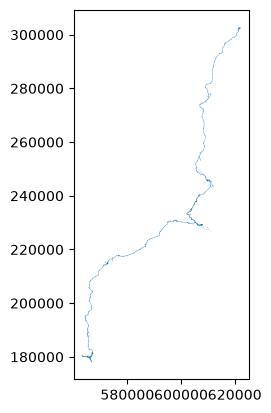

In [128]:
gdf_nt_route = gpd.read_file("../Routes/norwich-tilbury-boundary.geojson").to_crs("epsg:27700")
gdf_nt_route = gdf_nt_route.iloc[[2],:]
gdf_nt_route.plot()

D:\Profiles\Tim\AppData\Local\Temp\2\ipykernel_28844\948502922.py:9: FutureWarning: You are adding a column named 'geometry' to a GeoDataFrame constructed without an active geometry column. Currently, this automatically sets the active geometry column to 'geometry' but in the future that will no longer happen. Instead, either provide geometry to the GeoDataFrame constructor (GeoDataFrame(... geometry=GeoSeries()) or use `set_geometry('geometry')` to explicitly set the active geometry column.
  gdf_buffer["geometry"] = buffer
D:\Profiles\Tim\AppData\Local\Temp\2\ipykernel_28844\948502922.py:13: FutureWarning: You are adding a column named 'geometry' to a GeoDataFrame constructed without an active geometry column. Currently, this automatically sets the active geometry column to 'geometry' but in the future that will no longer happen. Instead, either provide geometry to the GeoDataFrame constructor (GeoDataFrame(... geometry=GeoSeries()) or use `set_geometry('geometry')` to explicitly set

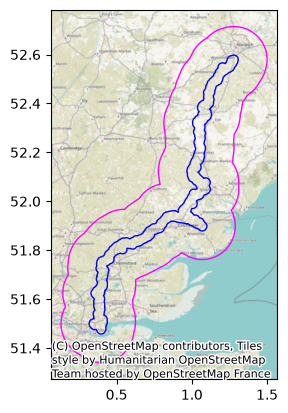

In [135]:
buffer = gdf_nt_route.buffer(15000)
buffer2 = gdf_nt_route.buffer(2000)

# The below is purely to get a look at the buffers.

bbox = box(*buffer.total_bounds)

gdf_buffer = gpd.GeoDataFrame()
gdf_buffer["geometry"] = buffer
gdf_buffer.set_crs("epsg:27700", inplace=True)

gdf_buffer2 = gpd.GeoDataFrame()
gdf_buffer2["geometry"] = buffer2
gdf_buffer2.set_crs("epsg:27700", inplace=True)

gdf_buffer = pd.concat([gdf_buffer, gdf_buffer2], axis = 0)
del gdf_buffer2

fig, ax = plt.subplots()
gdf_buffer.to_crs("epsg:4326").iloc[[0]].plot(ax = ax, edgecolor = 'magenta', color = 'none')
gdf_buffer.to_crs("epsg:4326").iloc[[1]].plot(ax = ax, edgecolor = 'blue', color = 'none')
cx.add_basemap(ax = ax, crs = "epsg:4326", zoom = 9)



(193408, 33)
(122145, 33)
(13648, 33)


<Axes: >

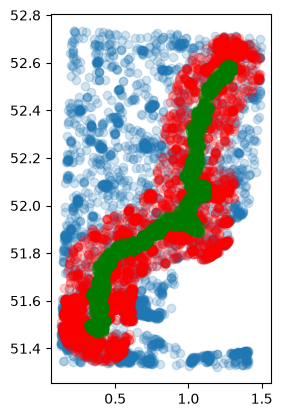

In [137]:
bbox_placenames = gpd.read_file(
    "../../OS Data/opname_gpkg_gb/Data/opname_gb.gpkg",
    bbox=bbox,
    # mask = buffer,
)
print(bbox_placenames.shape)

buffer1_placenames = gpd.read_file(
    "../../OS Data/opname_gpkg_gb/Data/opname_gb.gpkg",
    # bbox=bbox,
    mask = buffer,
)
print(buffer1_placenames.shape)

buffer2_placenames = gpd.read_file(
    "../../OS Data/opname_gpkg_gb/Data/opname_gb.gpkg",
    # bbox=bbox,
    mask = buffer2,
)
print(buffer2_placenames.shape)

fig, ax = plt.subplots()
bbox_placenames.sample(5000).to_crs("epsg:4326").plot(ax = ax, alpha = 0.2)
buffer1_placenames.sample(5000).to_crs("epsg:4326").plot(ax = ax, alpha = 0.2, color = 'red')
buffer2_placenames.sample(5000).to_crs("epsg:4326").plot(ax = ax, alpha = 0.2, color = 'green')



In [145]:
bbox_placenames["name1_lower"] = bbox_placenames["name1"].map(lambda s:s.lower())
buffer1_placenames["name1_lower"] = buffer1_placenames["name1"].map(lambda s:s.lower())
buffer2_placenames["name1_lower"] = buffer2_placenames["name1"].map(lambda s:s.lower())
bbox_placenames.sample(100)

,id,names_uri,name1,name1_lang,name2,name2_lang,type,local_type,most_detail_view_res,least_detail_view_res,...,county_unitary_type,region,region_uri,country,country_uri,related_spatial_object,same_as_dbpedia,same_as_geonames,geometry,name1_lower
12664,osgb4000000032998417,http://data.ordnancesurvey.co.uk/id/4000000032...,Gorrell Road,None,None,None,transportNetwork,Named Road,1000,20000,...,http://data.ordnancesurvey.co.uk/ontology/admi...,South East,http://data.ordnancesurvey.co.uk/id/7000000000...,England,http://data.ordnancesurvey.co.uk/id/country/en...,None,None,None,POINT (611123 166028),gorrell road
11470,osgb4000000030508009,http://data.ordnancesurvey.co.uk/id/4000000030...,Sanspareil Avenue,None,None,None,transportNetwork,Named Road,3000,20000,...,http://data.ordnancesurvey.co.uk/ontology/admi...,South East,http://data.ordnancesurvey.co.uk/id/7000000000...,England,http://data.ordnancesurvey.co.uk/id/country/en...,None,None,None,POINT (594126 172532),sanspareil avenue
48919,SS156QT,http://data.ordnancesurvey.co.uk/id/postcodeun...,SS15 6QT,None,None,None,other,Postcode,3500,18000,...,http://data.ordnancesurvey.co.uk/ontology/admi...,Eastern,http://data.ordnancesurvey.co.uk/id/7000000000...,England,http://data.ordnancesurvey.co.uk/id/country/en...,None,None,None,POINT (567027 188603),ss15 6qt
14630,osgb4000000074626803,http://data.ordnancesurvey.co.uk/id/4000000074...,Crowdown Wood,None,None,None,landcover,Woodland Or Forest,2000,400000,...,http://data.ordnancesurvey.co.uk/ontology/admi...,South East,http://data.ordnancesurvey.co.uk/id/7000000000...,England,http://data.ordnancesurvey.co.uk/id/country/en...,None,None,None,POINT (619659 165434),crowdown wood
47693,CM40NL,http://data.ordnancesurvey.co.uk/id/postcodeun...,CM4 0NL,None,None,None,other,Postcode,3500,18000,...,http://data.ordnancesurvey.co.uk/ontology/admi...,Eastern,http://data.ordnancesurvey.co.uk/id/7000000000...,England,http://data.ordnancesurvey.co.uk/id/country/en...,None,None,None,POINT (563857 200203),cm4 0nl
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40847,RM95LJ,http://data.ordnancesurvey.co.uk/id/postcodeun...,RM9 5LJ,None,None,None,other,Postcode,3500,18000,...,http://data.ordnancesurvey.co.uk/ontology/admi...,London,http://data.ordnancesurvey.co.uk/id/7000000000...,England,http://data.ordnancesurvey.co.uk/id/country/en...,None,None,None,POINT (548306 185777),rm9 5lj
171316,osgb4000000030537605,http://data.ordnancesurvey.co.uk/id/4000000030...,Newton Hall Gardens,None,None,None,transportNetwork,Named Road,1000,20000,...,http://data.ordnancesurvey.co.uk/ontology/admi...,Eastern,http://data.ordnancesurvey.co.uk/id/7000000000...,England,http://data.ordnancesurvey.co.uk/id/country/en...,None,None,None,POINT (586658 192988),newton hall gardens
66557,CO93RH,http://data.ordnancesurvey.co.uk/id/postcodeun...,CO9 3RH,None,None,None,other,Postcode,3500,18000,...,http://data.ordnancesurvey.co.uk/ontology/admi...,Eastern,http://data.ordnancesurvey.co.uk/id/7000000000...,England,http://data.ordnancesurvey.co.uk/id/country/en...,None,None,None,POINT (578626 232956),co9 3rh
189480,CO154DZ,http://data.ordnancesurvey.co.uk/id/postcodeun...,CO15 4DZ,None,None,None,other,Postcode,3500,18000,...,http://data.ordnancesurvey.co.uk/ontology/admi...,Eastern,http://data.ordnancesurvey.co.uk/id/7000000000...,England,http://data.ordnancesurvey.co.uk/id/country/en...,None,None,None,POINT (617392 216608),co15 4dz


In [180]:
candidate_names_not_found = set()
found_multiple = set()

assert bbox_placenames.crs.name == 'OSGB36 / British National Grid'
assert bbox_placenames.crs.name == 'OSGB36 / British National Grid'
assert bbox_placenames.crs.name == 'OSGB36 / British National Grid'

gdf_located_places = gpd.GeoDataFrame(columns = ["place_name", "type", "local_type", "postcode_district", "populated_place", "county_unitary", "geometry", "approx_match_flag"])

def look_for_possible_placename(candidate_name, adjusted_name = None):


    if not adjusted_name:
        original_name = True
        adjusted_name = candidate_name.strip()
    else:
        original_name = False

    results = bbox_placenames.loc[bbox_placenames["name1_lower"] == adjusted_name.lower()]

    if results.shape[0] == 0:
        if len(adjusted_name.strip().split(" ")) > 1:
            # If it's a multiple word string like 'Broomfield Library' we try our luck with just the first word to get an approx location.
            # We use recursion to do this.
            print(f"recursing {adjusted_name.strip().split(" ")}")
            look_for_possible_placename(candidate_name, adjusted_name.strip().split(" ")[0])
        else:
            candidate_names_not_found.add(candidate_name)
            return

    if results.shape[0] > 1:
        # If results are all nearby anyway, we can just accept the first result.
        total_bounds = results["geometry"].total_bounds
        if (abs(total_bounds[0] - total_bounds[2]) < 1000) and (abs(total_bounds[1] - total_bounds[3]) < 1000):
            results = results.iloc[[0]]

    if results.shape[0] > 1:
        # Try a tigher buffer:
        results = buffer1_placenames.loc[buffer1_placenames["name1_lower"] == adjusted_name.lower()]

    if results.shape[0] > 1:
        # Try a tigher buffer:
        results = buffer2_placenames.loc[buffer2_placenames["name1_lower"] == adjusted_name.lower()]

    if results.shape[0] > 1:
        # If results are all nearby anyway, we can just accept the first.
        total_bounds = results["geometry"].total_bounds
        if (abs(total_bounds[0] - total_bounds[2]) < 1000) and (abs(total_bounds[1] - total_bounds[3]) < 1000):
            results = results.iloc[[0]]


    if results.shape[0] == 1:
        results = results.iloc[0]
        newind = gdf_located_places.shape[0]
        gdf_located_places.loc[newind, "place_name"] = candidate_name
        gdf_located_places.loc[newind, "type"] = results["type"]
        gdf_located_places.loc[newind, "local_type"] = results["local_type"]
        gdf_located_places.loc[newind, "postcode_district"] = results["postcode_district"]
        gdf_located_places.loc[newind, "populated_place"] = results["populated_place"]
        gdf_located_places.loc[newind, "county_unitary"] = results["county_unitary"]
        gdf_located_places.loc[newind, "geometry"] = results["geometry"]
        gdf_located_places.loc[newind, "approx_match_flag"] = (not original_name)
    else:
        # Means that multiple were found and we couldn't make a good guess at which was meant.
        # (of course a sophisticated method might look for clustering with other place names mentioned!)
        found_multiple.add(candidate_name)


for candidate_name in list(unique_candidate_names):
    look_for_possible_placename(candidate_name)





recursing ['PLEASE', 'STOP', 'THE', 'PYLONS']
recursing ['Site', 'Visit', 'Guidance', 'Document']
recursing ['Simon', 'Neesam']
recursing ['Hinkley', 'Point', 'C']
recursing ['Green', 'Book']
recursing ['Viability', 'Impact']
recursing ['National', 'Grid', 'Design', 'Development', 'Report']
recursing ['Nicki', 'Lyden']
recursing ['Gliding', 'Club']
recursing ['Leading', 'Planning', 'Barrister']
recursing ['Cable', 'Sealing', 'End', 'Compound', 'Site']
recursing ['Special', 'Area']
recursing ['Mike', 'Kent', 'Honey']
recursing ['Companies', 'House']
recursing ['Unacceptable', 'Construction', 'Disruption']
recursing ['Spanish', 'Armada']
recursing ['Consider', 'Reasonable', 'Alternatives']
recursing ['Emma', 'L', 'Harrold']
recursing ['Great', 'Grid', 'Upgrade']
recursing ['U', 'S']
recursing ['UKPN', 'Undergrounding']
recursing ['Rivers', 'Wid']
recursing ['Alison', 'Ellis']
recursing ['Welfare', 'Services']
recursing ['THE', 'OFFSHORE', 'ROUTE', 'IS']
recursing ['Black', 'Worcester']
r

In [168]:
sorted(list(candidate_names_not_found))
# Concerned:
# Bellway, Boyton Hall, Broadview Farm, Broards Green
# Bushwood Farm, Buttevelyan, Chelmsford Rd, Chignal St, Colne River, Debden
# Wattisham Station, West Cottage, Took-Kirby, Tibernham, Thornham Parva

# Are some of the codes for pylons? Pylons are coded as RG__ or TB__ by the look of it. Possibly CM__

# Abby Bebbington, Acaster, Alborough House, Aldeburgh, Aldham Church, Altham, Ardleigh Conservation Area, Arnhem, Ash Tree Corner
# etc. etc.
# etc. etc.

['A&#39',
 'A&amp',
 'A-road',
 'A1',
 'A1 Environmental Statement Appendix',
 'A1013 Stanford Road',
 'A12 Marks Tey',
 'A12 Truck',
 'A12 Trunk Road',
 'A12 Widening DCO',
 'A12 Works',
 'A120 Coggeshall',
 'A127 Southend Arterial Road',
 'A129 London Road',
 'A13 Stanford-le-Hope Bypass',
 'A16',
 'A2 Environmental Statement Appendix',
 'A3',
 'A3 Qualitative Groundwater Risk Assessment',
 'A3 Visual Baseline Assessment',
 'A4 Environmental Statement Appendix',
 'A4 Hydrogeological Risk Assessment',
 'A7',
 'A7 Environmental Statement Appendix',
 'A9',
 'AA12842',
 'ABN Amro',
 'ABSOLUTELY NOT NECESSARY',
 'AC',
 'AC EMF',
 'AC OHL',
 'ACDC',
 'AD1103',
 'AD1134',
 'AD43',
 'AD500',
 'ADMISSIONS BY NATIONAL GRID OF HARM TO THE DEDHAM VALE AND ERRORS IN THE APPLICATION OF NATIONAL POLICY',
 'AECOM Writtle Design Guide',
 'AECOM Writtle Design Guide March',
 'AENC-ARC-ENV-REP-0125',
 'AENC-LSTC-ENG-DWG-0003 Sheet',
 'AEP',
 'AFTER National Grid',
 'AGTR',
 'AI-supported',
 'AIA',
 'AI

In [165]:
len(found_multiple), found_multiple
# Tightening the search buffer reduced these from 275 to 149.

(148,
 {'A10',
  'A1060',
  'A1071',
  'A11',
  'A1124',
  'A120',
  'A128',
  'A130',
  'A131',
  'A134',
  'A137',
  'A14',
  'A140',
  'A2',
  'A414',
  'Acacia Road',
  'Ardleigh Road',
  'B1018',
  'B1078',
  'B1113',
  'B1135',
  'B1508',
  'Bentley',
  'Bentley Road',
  'Birchwood',
  'Birchwood Road',
  'Boreham Road',
  'Boxhouse Lane',
  'Boxted Road',
  'Braintree Road',
  'Brentwood',
  'Brentwood Road',
  'Brick Kiln Lane',
  'Brick Kiln Wood',
  'Bridge Road',
  'Broad Green',
  'Bromley Road',
  'Brook Road',
  'Broomfield',
  'Buckingham Hill Road',
  'Bullen Lane',
  'Burgate Road',
  'Bushy Wood',
  'California',
  'Chelmsford Road',
  'Chignal Road',
  'Church End',
  'Church Hill',
  'Church Lane',
  'Church Road',
  'Clockhouse Lane',
  'Coggeshall Road',
  'Colchester',
  'Colchester Road',
  'Colne Valley',
  'Common Road',
  'Cow Lane',
  'Cowpasture Lane',
  'Creeting Lane',
  'Cressing',
  'Dam Lane',
  'Darrow Lane',
  'Dead Lane',
  'Debenham Road',
  'Dedha

In [118]:
pd.Series(list(candidate_names_not_found)).sample(500)

# notley, kings farmhouse, southwood, River Colne, ingatestone hall,

1771       Navigation Regulation
5924                       Surey
3146          Red Brick Cottages
260                  Biosecurity
2255           Docuras Farm Road
                  ...           
4955                         T73
5213                    Cycle UK
4740    Tree Preservation Orders
4261    Amenity Impacts Contrary
1096                         CO4
Length: 500, dtype: object

In [166]:
gdf_located_places.sort_values("place_name")

# And of course some places are mentioned multiple times, so we have more than 262 data items here to work with.

# Using just OS named places, we identified 262 places mentioned in our representations (without attachments).
# By filtering down multiple matches by accepting the ones in the tigher bufferzones, increased this to 316.
# By also accepting multiple matches that are within 1000mx1000m, increased further to 391.

# Lookup pylons as RG__ or TB__ or pylon RG__, pylon TB__ will also be of use.

# Looking up pylons, plus lookups using nominatim, should increase this further.



,place_name,type,local_type,postcode_district,populated_place,county_unitary,geometry
207,A1066,transportNetwork,Section Of Numbered Road,IP22,Diss,Norfolk,POINT (612027 279539)
48,A1089,transportNetwork,Numbered Road,RM17,None,Thurrock,POINT (563424 178084)
324,A1120,transportNetwork,Section Of Numbered Road,IP14,None,Suffolk,POINT (606133 257556)
183,A12,transportNetwork,Numbered Road,CO4,None,Essex,POINT (598938 228951)
22,A129,transportNetwork,Section Of Numbered Road,CM13,Brentwood,Essex,POINT (562133 195122)
...,...,...,...,...,...,...,...
139,Writtle College,other,Higher or University Education,CM1,None,Essex,POINT (566194 206695)
219,Wymondham,transportNetwork,Railway Station,NR18,Wymondham,Norfolk,POINT (611417 300970)
175,Wymondham Road,transportNetwork,Section Of Named Road,NR16,Wreningham,Norfolk,POINT (615442 298681)
11,Yaxley,populatedPlace,Village,IP23,None,Suffolk,POINT (612007 273828)


<Axes: >

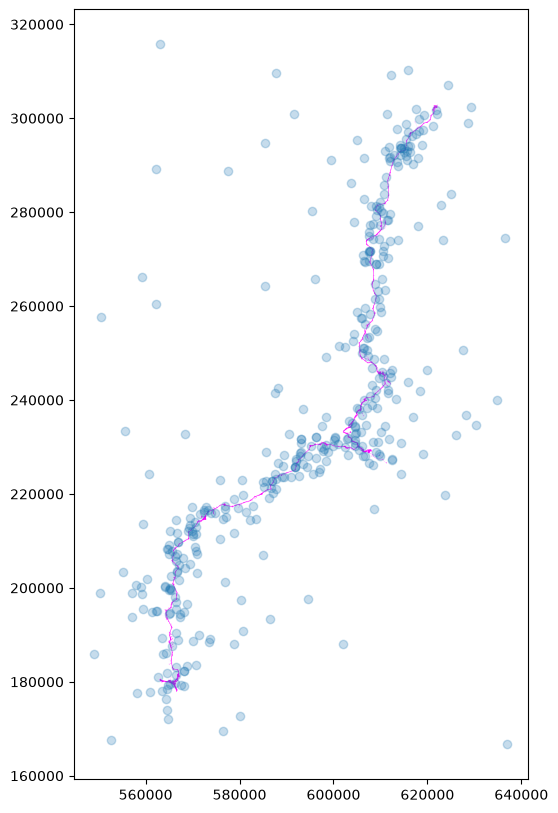

In [167]:
fig, ax = plt.subplots(figsize = (10, 10))
gdf_nt_route.plot(ax = ax, color = "magenta")
gdf_located_places.plot(ax = ax, alpha = 0.25)

In [ ]:
# Where the first word of a multiword phrase is matchable, it should go down as an additional match for that place. (Though ultimately we will only count one mention per representation.)
# We might need to check for letters that have been copied and pasted as these do not necessarily represent genuine concern about all the places mentioned.